In [ ]:
#Libraries
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from IPython.display import Markdown
import tabulate
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

In [64]:
ozone = pd.read_excel(r"C:\Users\darre\OneDrive\Documents\STATS 780\Assignment 2\Ozone.xlsx", sheet_name='Sheet1')
particulate = pd.read_excel(r"C:\Users\darre\OneDrive\Documents\STATS 780\Assignment 2\Particulate.xlsx", sheet_name='Sheet1')

In [65]:
duplicate_observations_o = ozone[
    ozone.duplicated(subset=["Station ID", "Date"], keep=False)
].sort_values(["Station ID", "Date"])

print(duplicate_observations_o.head())
print(f"Duplicate observation rows (ozone): {len(duplicate_observations_o)}")

    Station ID Pollutant       Date  H01  H02  H03  H04  H05  H06  H07  ...  \
43       29118     Ozone 2025-02-13   21   20   16   13    9   11    8  ...   
44       29118     Ozone 2025-02-13 -999 -999 -999 -999 -999 -999 -999  ...   

    H15  H16  H17  H18  H19  H20  H21  H22  H23  H24  
43   34   37   39   38   38   38   36   37 -999 -999  
44   40   41   42   38   34   32   32   34   31   29  

[2 rows x 27 columns]
Duplicate observation rows (ozone): 2


In [ ]:
# Check duplicate observations
duplicate_observations_p = particulate[
    particulate.duplicated(subset=["Station ID", "Date"], keep=False)
].sort_values(["Station ID", "Date"])

print(duplicate_observations_p.head())
print(f"Duplicate observation rows (particulate): {len(duplicate_observations_p)}")


    Station ID                Pollutant       Date  H01  H02  H03  H04  H05  \
43       29118  Fine Particulate Matter 2025-02-13   11    6    7    6    6   
44       29118  Fine Particulate Matter 2025-02-13 -999 -999 -999 -999 -999   

    H06  H07  ...  H15  H16  H17  H18  H19  H20  H21  H22  H23  H24  
43    6    7  ...    5    5    4    3    3    3    3    3 -999 -999  
44 -999 -999  ...    7    7    7    9   12   15   15   15   15   16  

[2 rows x 27 columns]
Duplicate observation rows (particulate): 2


In [66]:
# changing the second 2025-02-13 to 2025-02-14, assuming it is 
# a measurement error
ozone["Date"] = pd.to_datetime(ozone["Date"])

feb13 = (ozone["Date"].dt.month == 2) & (ozone["Date"].dt.day == 13)
positions = np.flatnonzero(feb13.to_numpy())

if len(positions) < 2:
    raise ValueError("There are fewer than two February 13 rows.")

second_pos = positions[1]
date_col = ozone.columns.get_loc("Date")
ozone.iloc[second_pos, date_col] += pd.Timedelta(days=1)

In [67]:
particulate["Date"] = pd.to_datetime(particulate["Date"])

feb13 = (particulate["Date"].dt.month == 2) & (particulate["Date"].dt.day == 13)
positions = np.flatnonzero(feb13.to_numpy())

if len(positions) < 2:
    raise ValueError("There are fewer than two February 13 rows.")

second_pos = positions[1]
date_col = particulate.columns.get_loc("Date")
particulate.iloc[second_pos, date_col] += pd.Timedelta(days=1)

In [9]:
hour_columns = [f"H{i:02d}" for i in range(1, 25)]

particulate = particulate.melt(
    id_vars=["Station ID", "Pollutant", "Date"],
    value_vars=hour_columns,
    var_name="Hour",
    value_name="Concentration"
)

particulate["Date"] = (
    pd.to_datetime(particulate["Date"])
    + pd.to_timedelta(
        particulate["Hour"].str[1:].astype(int) - 1,
        unit="h"
    )
)

particulate = (
    particulate
    .drop(columns="Hour")
    .sort_values(["Station ID", "Pollutant", "Date"])
    .reset_index(drop=True)
)



In [ ]:
ozone = ozone.melt(
    id_vars=["Station ID", "Pollutant", "Date"],
    value_vars=hour_columns,
    var_name="Hour",
    value_name="Concentration"
)

ozone["Date"] = (
    pd.to_datetime(ozone["Date"])
    + pd.to_timedelta(
        ozone["Hour"].str[1:].astype(int) - 1,
        unit="h"
    )
)

ozone = (
    ozone
    .drop(columns="Hour")
    .sort_values(["Station ID", "Pollutant", "Date"])
    .reset_index(drop=True)
)

In [13]:
ozone = (
    ozone
    .rename(columns={"Concentration": "ozone"})
    .drop(columns = 'Pollutant')
)

In [15]:
particulate = (
    particulate
    .rename(columns={"Concentration": "PM2.5"})
    .drop(columns = 'Pollutant')
)

In [ ]:
merge = pd.merge(ozone, particulate, on='Date', how='inner')

,Station ID_x,Date,ozone,Station ID_y,PM2.5
0,29118,2025-01-01 00:00:00,19,29118,7
1,29118,2025-01-01 01:00:00,23,29118,2
2,29118,2025-01-01 02:00:00,23,29118,1
3,29118,2025-01-01 03:00:00,23,29118,1
4,29118,2025-01-01 04:00:00,24,29118,0
...,...,...,...,...,...
8755,29118,2025-12-31 19:00:00,31,29118,3
8756,29118,2025-12-31 20:00:00,34,29118,2
8757,29118,2025-12-31 21:00:00,38,29118,1
8758,29118,2025-12-31 22:00:00,35,29118,1


In [17]:
merge = (
    merge
    .rename(columns={"Station ID_x": "Station ID"})
    .drop(columns= 'Station ID_y')
)

In [ ]:
#convert invalid values to NaNs so they don't become outliers
merge["ozone"] = merge["ozone"].replace([9999,-999,999], np.nan)
merge["PM2.5"] = merge["PM2.5"].replace([9999,-999,999], np.nan)

In [ ]:
# the number of NaN's matches the number of invalid numbers
print(merge[["ozone", "PM2.5"]].isna().sum())

ozone    129
PM2.5     78
dtype: int64


In [22]:
merge.loc[
    merge["Date"].dt.date == pd.Timestamp("2025-01-13").date()]

,Station ID,Date,ozone,PM2.5
288,29118,2025-01-13 00:00:00,32.0,11.0
289,29118,2025-01-13 01:00:00,32.0,11.0
290,29118,2025-01-13 02:00:00,31.0,11.0
291,29118,2025-01-13 03:00:00,NaN,11.0
292,29118,2025-01-13 04:00:00,31.0,13.0
293,29118,2025-01-13 05:00:00,31.0,8.0
294,29118,2025-01-13 06:00:00,26.0,7.0
295,29118,2025-01-13 07:00:00,23.0,9.0
296,29118,2025-01-13 08:00:00,22.0,8.0
297,29118,2025-01-13 09:00:00,21.0,10.0


In [23]:
# Used linear interpolation to fill in missing values

merge["Date"] = pd.to_datetime(merge["Date"], errors="coerce")
merge = merge.sort_values(["Station ID", "Date"])

# Interpolate measurement columns, not the numeric station identifier.
value_cols = [
    col for col in merge.select_dtypes(include="number").columns
    if col != "Station ID"
]

# Interpolate using actual time intervals, independently for each station.
merge[value_cols] = (
    merge.set_index("Date")
    .groupby("Station ID")[value_cols]
    .transform(
        lambda values: values.interpolate(
            method="time",
            limit_area="inside",
        )
    )
    .to_numpy()
)

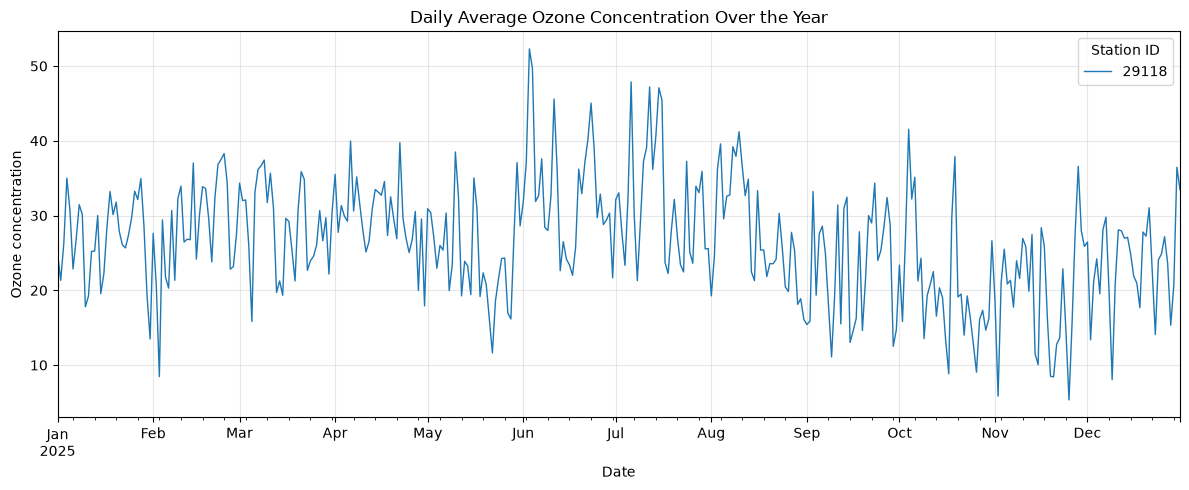

In [ ]:
#takes hourly ozone measurements, calculates the average concentration 
#for each day, and plots those daily averages over the year.
ozone_col = "ozone" 

df = merge.copy()
df = df.dropna(subset=["Date", ozone_col])
df["_day"] = df["Date"].dt.floor("D")

if "Station ID" in df.columns:
    daily = df.groupby(["_day", "Station ID"])[ozone_col].mean().unstack()
    ax = daily.plot(figsize=(12, 5), linewidth=1)
    ax.legend(title="Station ID")
else:
    daily = df.groupby("_day")[ozone_col].mean()
    ax = daily.plot(figsize=(12, 5), linewidth=1)

ax.set(
    title="Daily Average Ozone Concentration Over the Year",
    xlabel="Date",
    ylabel="Ozone concentration",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

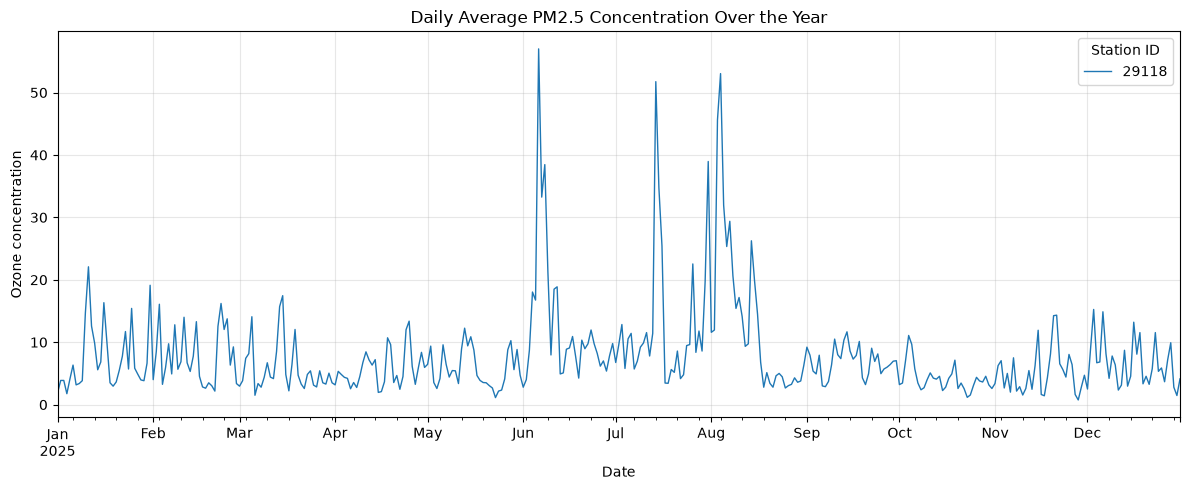

In [ ]:
#takes hourly PM2.5 measurements, calculates the average concentration 
#for each day, and plots those daily averages over the year.

pm_col = "PM2.5" 

df = merge.copy()
df = df.dropna(subset=["Date", pm_col])
df["_day"] = df["Date"].dt.floor("D")

if "Station ID" in df.columns:
    daily = df.groupby(["_day", "Station ID"])[pm_col].mean().unstack()
    ax = daily.plot(figsize=(12, 5), linewidth=1)
    ax.legend(title="Station ID")
else:
    daily = df.groupby("_day")[pm_col].mean()
    ax = daily.plot(figsize=(12, 5), linewidth=1)

ax.set(
    title="Daily Average PM2.5 Concentration Over the Year",
    xlabel="Date",
    ylabel="Ozone concentration",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Calculating dominant frequency and dominant spectral power
# for ozone and PM2.5, adding them as features to merge

# Keep missing observations; sort the hourly data without dropping rows.
merge["Date"] = pd.to_datetime(merge["Date"])
merge = merge[["Date", "ozone", "PM2.5"]].sort_values("Date")

if merge.empty:
    raise ValueError("There are no observations to process.")
if merge["Date"].duplicated().any():
    raise ValueError("Date must contain unique timestamps.")

# Insert missing hourly timestamps so every window represents 24 hours.
intervals = merge["Date"].diff().dropna().dt.total_seconds()
if (intervals % 3600 != 0).any():
    raise ValueError("Dates must lie on an hourly grid.")

merge = merge.set_index("Date")
hourly_index = pd.date_range(merge.index[0], merge.index[-1], freq="h")
merge = merge.reindex(hourly_index)
merge.index.name = "Date"

window_size = 24
frequencies = np.fft.rfftfreq(window_size, d=1)  # cycles per hour

# Each feature uses the 24 hours ending at that row.
for pollutant in ["ozone", "PM2.5"]:
    dominant_frequency = np.full(len(merge), np.nan)
    dominant_power = np.full(len(merge), np.nan)

    for end in range(window_size - 1, len(merge)):
        start = end - window_size + 1
        window = merge[pollutant].iloc[start:end + 1].to_numpy(dtype=float)

        # Leave features missing if this window has any missing observations.
        if not np.isfinite(window).all():
            continue

        window = window - window.mean()
        power = np.abs(np.fft.rfft(window)) ** 2

        # Ignore the zero-frequency component.
        positive_power = power[1:]
        if positive_power.max() == 0:
            continue

        dominant_idx = np.argmax(positive_power) + 1
        dominant_frequency[end] = frequencies[dominant_idx]
        dominant_power[end] = power[dominant_idx]

    merge[f"{pollutant}_fft_dominant_frequency"] = dominant_frequency
    merge[f"{pollutant}_fft_dominant_power"] = dominant_power

# Keep Date as a regular column in the resulting DataFrame.
merge = merge.reset_index()

In [27]:
merge

,Date,ozone,PM2.5,ozone_fft_dominant_frequency,ozone_fft_dominant_power,PM2.5_fft_dominant_frequency,PM2.5_fft_dominant_power
0,2025-01-01 00:00:00,19.0,7.0,NaN,NaN,NaN,NaN
1,2025-01-01 01:00:00,23.0,2.0,NaN,NaN,NaN,NaN
2,2025-01-01 02:00:00,23.0,1.0,NaN,NaN,NaN,NaN
3,2025-01-01 03:00:00,23.0,1.0,NaN,NaN,NaN,NaN
4,2025-01-01 04:00:00,24.0,0.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
8755,2025-12-31 19:00:00,31.0,3.0,0.041667,1180.388435,0.041667,839.167744
8756,2025-12-31 20:00:00,34.0,2.0,0.041667,1161.556231,0.041667,839.167744
8757,2025-12-31 21:00:00,38.0,1.0,0.041667,1183.343493,0.041667,895.863224
8758,2025-12-31 22:00:00,35.0,1.0,0.041667,1109.718778,0.041667,939.531721


In [ ]:
# Check that timestamps are unique and exactly one hour apart.
dates = pd.to_datetime(merge["Date"], errors="raise")

if not dates.is_unique:
    raise ValueError("Date must contain unique timestamps.")

intervals = dates.diff().iloc[1:]

if not np.all(intervals.to_numpy() == pd.Timedelta(hours=1)):
    raise ValueError("Date must be a complete hourly timeline in chronological order.")

# Build features on a copy to preserve the original data.
feature_data = merge.copy()

statistical_feature_cols = []
window_size = 24

for pollutant in ("ozone", "PM2.5"):

    # Latest concentration
    latest_col = f"{pollutant}_latest"
    feature_data[latest_col] = feature_data[pollutant]
    statistical_feature_cols.append(latest_col)

    # 24-hour rolling window
    rolling = feature_data[pollutant].rolling(
        window=window_size,
        min_periods=window_size
    )

    # Rolling mean and standard deviation
    mean_col = f"{pollutant}_mean_24h"
    std_col = f"{pollutant}_std_24h"

    feature_data[mean_col] = rolling.mean()
    feature_data[std_col] = rolling.std()

    statistical_feature_cols.extend([mean_col, std_col])

# Create next-hour prediction targets
target_cols = [
    "ozone_target_next_hour",
    "PM2.5_target_next_hour"
]

feature_data[target_cols[0]] = feature_data["ozone"].shift(-1)
feature_data[target_cols[1]] = feature_data["PM2.5"].shift(-1)

# Identify existing FFT features
fft_feature_cols = [
    col for col in merge.columns
    if col.endswith((
        "_fft_dominant_frequency",
        "_fft_dominant_power"
    ))
]

# Combine statistical and FFT predictors
predictor_cols = statistical_feature_cols + fft_feature_cols

# Prepare dataset for machine learning
model_data = feature_data[
    ["Date", *predictor_cols, *target_cols]
].dropna(subset=[*predictor_cols, *target_cols]).copy()

# Display results
print("First five rows:")
print(model_data.head())

print("\nLast five rows:")
print(model_data.tail())

print("\nShape:", model_data.shape)
print("\nPredictor columns:", predictor_cols)

First five rows:
                  Date  ozone_latest  ozone_mean_24h  ozone_std_24h  \
23 2025-01-01 23:00:00          19.0       24.875000       3.745287   
24 2025-01-02 00:00:00          21.0       24.958333       3.629339   
25 2025-01-02 01:00:00          25.0       25.041667       3.605300   
26 2025-01-02 02:00:00          24.0       25.083333       3.586408   
27 2025-01-02 03:00:00          23.0       25.083333       3.586408   

    PM2.5_latest  PM2.5_mean_24h  PM2.5_std_24h  ozone_fft_dominant_frequency  \
23           3.0        1.916667       1.411649                      0.041667   
24           3.0        1.750000       0.944089                      0.041667   
25           2.0        1.750000       0.944089                      0.041667   
26           1.0        1.750000       0.944089                      0.041667   
27           1.0        1.750000       0.944089                      0.041667   

    ozone_fft_dominant_power  PM2.5_fft_dominant_frequency  \
23     

In [29]:
feature_data

,Date,ozone,PM2.5,ozone_fft_dominant_frequency,ozone_fft_dominant_power,PM2.5_fft_dominant_frequency,PM2.5_fft_dominant_power,ozone_latest,ozone_mean_3h,ozone_std_3h,...,PM2.5_mean_3h,PM2.5_std_3h,PM2.5_mean_6h,PM2.5_std_6h,PM2.5_mean_12h,PM2.5_std_12h,PM2.5_mean_24h,PM2.5_std_24h,ozone_target_next_hour,PM2.5_target_next_hour
0,2025-01-01 00:00:00,19.0,7.0,NaN,NaN,NaN,NaN,19.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,2.0
1,2025-01-01 01:00:00,23.0,2.0,NaN,NaN,NaN,NaN,23.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,1.0
2,2025-01-01 02:00:00,23.0,1.0,NaN,NaN,NaN,NaN,23.0,21.666667,2.309401,...,3.333333,3.214550,NaN,NaN,NaN,NaN,NaN,NaN,23.0,1.0
3,2025-01-01 03:00:00,23.0,1.0,NaN,NaN,NaN,NaN,23.0,23.000000,0.000000,...,1.333333,0.577350,NaN,NaN,NaN,NaN,NaN,NaN,24.0,0.0
4,2025-01-01 04:00:00,24.0,0.0,NaN,NaN,NaN,NaN,24.0,23.333333,0.577350,...,0.666667,0.577350,NaN,NaN,NaN,NaN,NaN,NaN,26.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2025-12-31 19:00:00,31.0,3.0,0.041667,1180.388435,0.041667,839.167744,31.0,28.333333,2.309401,...,5.333333,2.081666,6.166667,1.722401,5.833333,1.466804,4.250000,1.983629,34.0,2.0
8756,2025-12-31 20:00:00,34.0,2.0,0.041667,1161.556231,0.041667,839.167744,34.0,30.666667,3.511885,...,3.666667,2.081666,5.500000,2.428992,5.666667,1.775251,4.250000,1.983629,38.0,1.0
8757,2025-12-31 21:00:00,38.0,1.0,0.041667,1183.343493,0.041667,895.863224,38.0,34.333333,3.511885,...,2.000000,1.000000,4.500000,2.880972,5.333333,2.229282,4.166667,2.078182,35.0,1.0
8758,2025-12-31 22:00:00,35.0,1.0,0.041667,1109.718778,0.041667,939.531721,35.0,35.666667,2.081666,...,1.333333,0.577350,3.333333,2.581989,4.833333,2.480225,4.125000,2.132818,38.0,2.0


In [36]:
model_data.head()

,Date,ozone_latest,ozone_mean_24h,ozone_std_24h,PM2.5_latest,PM2.5_mean_24h,PM2.5_std_24h,ozone_fft_dominant_frequency,ozone_fft_dominant_power,PM2.5_fft_dominant_frequency,PM2.5_fft_dominant_power,ozone_target_next_hour,PM2.5_target_next_hour
23,2025-01-01 23:00:00,19.0,24.875000,3.745287,3.0,1.916667,1.411649,0.041667,1978.619355,0.125000,140.083261,21.0,3.0
24,2025-01-02 00:00:00,21.0,24.958333,3.629339,3.0,1.750000,0.944089,0.041667,1862.526975,0.083333,71.641016,25.0,2.0
25,2025-01-02 01:00:00,25.0,25.041667,3.605300,2.0,1.750000,0.944089,0.041667,1724.275013,0.083333,71.641016,24.0,1.0
26,2025-01-02 02:00:00,24.0,25.083333,3.586408,1.0,1.750000,0.944089,0.041667,1647.780062,0.083333,71.641016,23.0,1.0
27,2025-01-02 03:00:00,23.0,25.083333,3.586408,1.0,1.750000,0.944089,0.041667,1647.780062,0.083333,71.641016,18.0,1.0


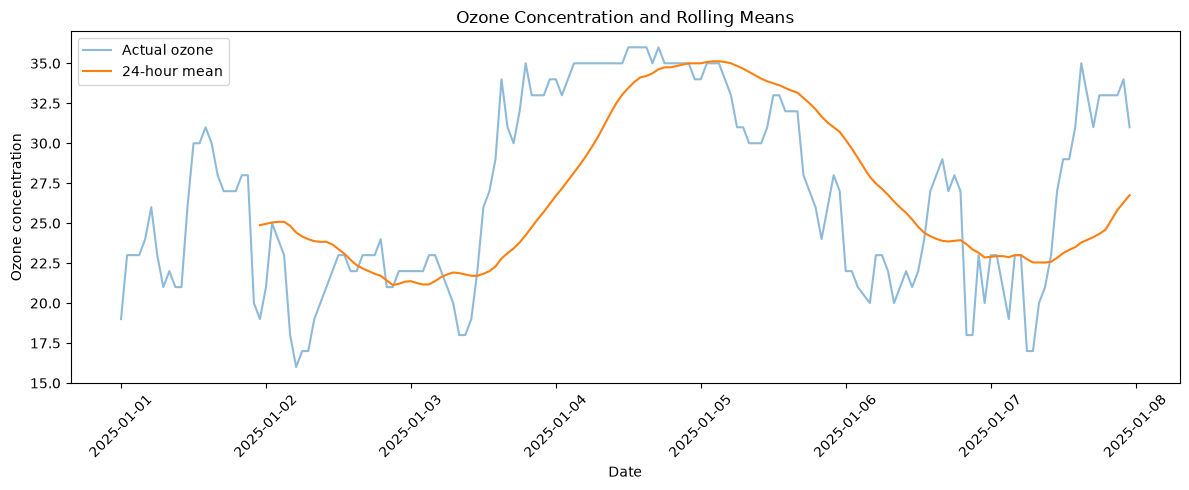

In [ ]:
# Examine one week
plot_data = feature_data.loc[
    (feature_data["Date"] >= "2025-01-01") &
    (feature_data["Date"] < "2025-01-08")
]

plt.figure(figsize=(12, 5))

plt.plot(plot_data["Date"], plot_data["ozone"],
         label="Actual ozone", alpha=0.5)

plt.plot(
    plot_data["Date"],
    plot_data[f"ozone_mean_24h"],
    label=f"{window}-hour mean"
)

plt.xlabel("Date")
plt.ylabel("Ozone concentration")
plt.title("Ozone Concentration and Rolling Means")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

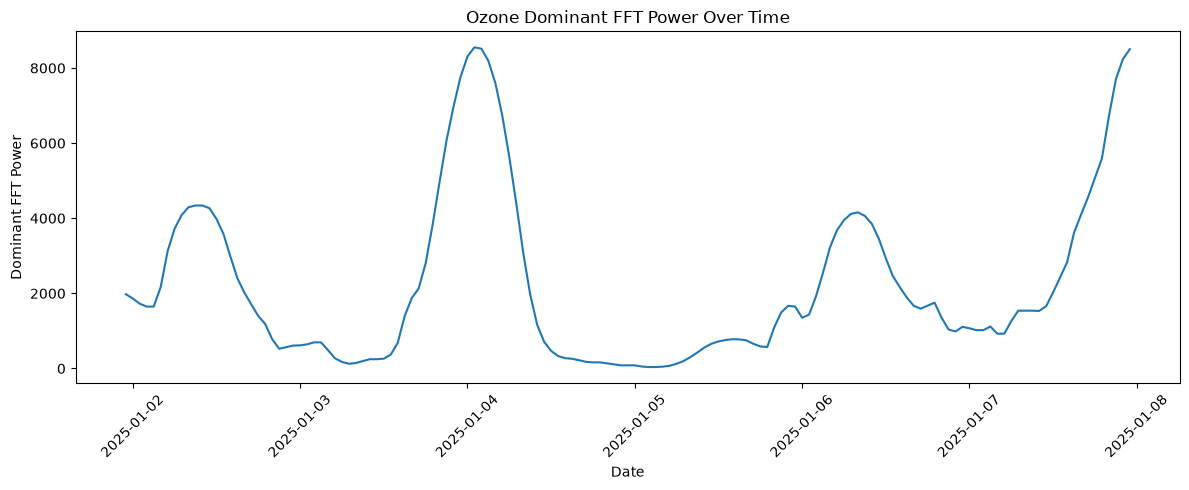

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["Date"],
    plot_data["ozone_fft_dominant_power"]
)

plt.xlabel("Date")
plt.ylabel("Dominant FFT Power")
plt.title("Ozone Dominant FFT Power Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Training: January–August
train = model_data.loc[
    model_data["Date"] < "2025-08-31 23:00"
].copy()

# Validation: September
validation = model_data.loc[
    (model_data["Date"] >= "2025-09-01") &
    (model_data["Date"] < "2025-09-30 23:00")
].copy()

# Testing: October–December
test = model_data.loc[
    model_data["Date"] >= "2025-10-01"
].copy()

X_train = train[predictor_cols]
X_val = validation[predictor_cols]

targets = {
    "Ozone": "ozone_target_next_hour",
    "PM2.5": "PM2.5_target_next_hour"
}

In [ ]:
# Finding optimal tree depth
depths = [1,2,3,4,5,6,7,8]

depth_results = []

for pollutant, target in targets.items():

    y_train = train[target]
    y_val = validation[target]

    for depth in depths:

        tree = DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        )
        tree.fit(X_train, y_train)

        # Predictions on training and validation data
        train_predictions = tree.predict(X_train)
        val_predictions = tree.predict(X_val)

        # Calculate RMSE
        train_rmse = np.sqrt(
            mean_squared_error(y_train, train_predictions)
        )

        val_rmse = np.sqrt(
            mean_squared_error(y_val, val_predictions)
        )

        depth_results.append({
            "Pollutant": pollutant,
            "Max Depth": depth,
            "Training RMSE": train_rmse,
            "Validation RMSE": val_rmse
        })

depth_results_df = pd.DataFrame(depth_results)

print(depth_results_df)

  Pollutant  Max Depth  Training RMSE  Validation RMSE
0     Ozone          1       8.869908        11.007288
1     Ozone          2       6.220353         7.125294
2     Ozone          3       4.998912         5.853741
3     Ozone          4       4.620769         5.690753
4     Ozone          5       4.505789         5.547018


In [ ]:
# Tuning number of trees
n_trees = [10, 50, 100, 200, 500]

tree_results = []

for pollutant, target in targets.items():

    y_train = train[target]
    y_val = validation[target]

    for n in n_trees:

        models = {
            "Bagging": BaggingRegressor(
                estimator=DecisionTreeRegressor(),
                n_estimators=n,
                random_state=42,
                n_jobs=-1
            ),

            "Random Forest": RandomForestRegressor(
                n_estimators=n,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            )
        }

        for name, model in models.items():

            model.fit(X_train, y_train)

            # Training and validation predictions
            train_predictions = model.predict(X_train)
            val_predictions = model.predict(X_val)

            # Calculate RMSE
            train_rmse = np.sqrt(
                mean_squared_error(y_train, train_predictions)
            )

            val_rmse = np.sqrt(
                mean_squared_error(y_val, val_predictions)
            )

            tree_results.append({
                "Pollutant": pollutant,
                "Model": name,
                "Number of Trees": n,
                "Training RMSE": train_rmse,
                "Validation RMSE": val_rmse
            })

tree_results_df = pd.DataFrame(tree_results)

print(tree_results_df)

  Pollutant          Model  Number of Trees  Training RMSE  Validation RMSE
0     Ozone        Bagging               10       2.073889         2.550454
1     Ozone  Random Forest               10       2.033693         2.423090
2     Ozone        Bagging               50       1.838055         2.284910
3     Ozone  Random Forest               50       1.749711         2.103283
4     Ozone        Bagging              100       1.806487         2.256712


In [ ]:
# Implementing decision trees, bagging, random forests

# Chronological split
train = model_data.loc[
    model_data["Date"] < "2025-10-01"
].copy()

test = model_data.loc[
    model_data["Date"] >= "2025-10-01"
].copy()

X_train = train[predictor_cols]
X_test = test[predictor_cols]

targets = {
    "Ozone": "ozone_target_next_hour",
    "PM2.5": "PM2.5_target_next_hour"
}

models = {
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),

    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
            
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for pollutant, target in targets.items():

    y_train = train[target]
    y_test = test[target]

    for name, model in models.items():

        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)

        predictions = fitted_model.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        rmse = mean_squared_error(
            y_test, predictions
        ) ** 0.5

        results.append({
            "Pollutant": pollutant,
            "Model": name,
            "MAE": mae,
            "RMSE": rmse
        })

results_df = pd.DataFrame(results)

print(results_df)

  Pollutant          Model       MAE      RMSE
0     Ozone  Decision Tree  2.969639  4.735327
1     Ozone        Bagging  2.920348  4.248946
2     Ozone  Random Forest  3.166003  4.518575
3     PM2.5  Decision Tree  0.940059  1.620337
4     PM2.5        Bagging  0.908799  1.390408
5     PM2.5  Random Forest  0.972473  1.342306


In [ ]:
# Multivariate random forest

target_cols = [
    "ozone_target_next_hour",
    "PM2.5_target_next_hour"
]

Y_train = train[target_cols]
Y_test = test[target_cols]

joint_rf = RandomForestRegressor(
    n_estimators=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

joint_rf.fit(X_train, Y_train)

joint_predictions = joint_rf.predict(X_test)

for i, pollutant in enumerate(["Ozone", "PM2.5"]):

    mae = mean_absolute_error(
        Y_test.iloc[:, i],
        joint_predictions[:, i]
    )

    rmse = mean_squared_error(
        Y_test.iloc[:, i],
        joint_predictions[:, i]
    ) ** 0.5

    print(f"{pollutant}: MAE = {mae:.3f}, RMSE = {rmse:.3f}")

Ozone: MAE = 3.281, RMSE = 4.671
PM2.5: MAE = 1.153, RMSE = 1.510


In [ ]:
# Identifying predictor importance using permutation importance
importance_results = []

for pollutant, target in targets.items():

    # Train random forest
    rf = RandomForestRegressor(
        n_estimators=100,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, train[target])

    # Calculate permutation importance on validation data
    perm = permutation_importance(
        rf,
        X_val,
        validation[target],
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    for predictor, importance in zip(
        predictor_cols,
        perm.importances_mean
    ):
        importance_results.append({
            "Pollutant": pollutant,
            "Predictor": predictor,
            "Importance": importance
        })

importance_df = pd.DataFrame(importance_results)

print(
    importance_df.sort_values(
        ["Pollutant", "Importance"],
        ascending=[True, False]
    )
)

   Pollutant                     Predictor  Importance
0      Ozone                  ozone_latest   17.523546
1      Ozone                ozone_mean_24h    2.516061
2      Ozone                 ozone_std_24h    2.227010
7      Ozone      ozone_fft_dominant_power    1.882186
5      Ozone                 PM2.5_std_24h    1.271291
4      Ozone                PM2.5_mean_24h    1.226974
9      Ozone      PM2.5_fft_dominant_power    1.149948
3      Ozone                  PM2.5_latest    1.109352
8      Ozone  PM2.5_fft_dominant_frequency    0.304576
6      Ozone  ozone_fft_dominant_frequency    0.039823
13     PM2.5                  PM2.5_latest    3.014794
15     PM2.5                 PM2.5_std_24h    0.628102
14     PM2.5                PM2.5_mean_24h    0.596765
19     PM2.5      PM2.5_fft_dominant_power    0.541586
11     PM2.5                ozone_mean_24h    0.523619
17     PM2.5      ozone_fft_dominant_power    0.413949
10     PM2.5                  ozone_latest    0.398874
12     PM2